## Task 2: Real Estate Housing Price Prediction (Ridge & Lasso Regression)

---

### 📌 Project Overview & Requirements
Implement an end-to-end supervised regression pipeline to predict median house values using the California housing dataset.
- Load the benchmark housing dataset via Pandas directly from the source URL[cite: 3]
- Engineer interaction features and impute missing values (e.g., `total_bedrooms`)
- Handle multicollinearity and encode categorical attributes (`ocean_proximity`)
- Train **Ordinary Least Squares (OLS)**, **Ridge (L2)**, and **Lasso (L1)** regression models
- Optimize hyperparameters using **GridSearchCV** across multiple alpha values
- Benchmark models using **RMSE**, **MAE**, and **$R^2$** scores
- Plot predicted vs. actual values and residual distribution curves

## Step 1: Downloading required libraries


In [25]:
!pip install scikit-learn pandas matplotlib seaborn


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Step 2: Importing all libraries

In [18]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Set plot aesthetic style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 100

## Step 3: Load Dataset from Source URL
Load the housing CSV dataset directly into a Pandas DataFrame[cite: 3].

In [19]:
url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
df = pd.read_csv(url)

print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## Step 4: Feature Engineering & Exploratory Correlation Heatmap
Engineer interaction features, inspect missing values, and visualize feature correlations.

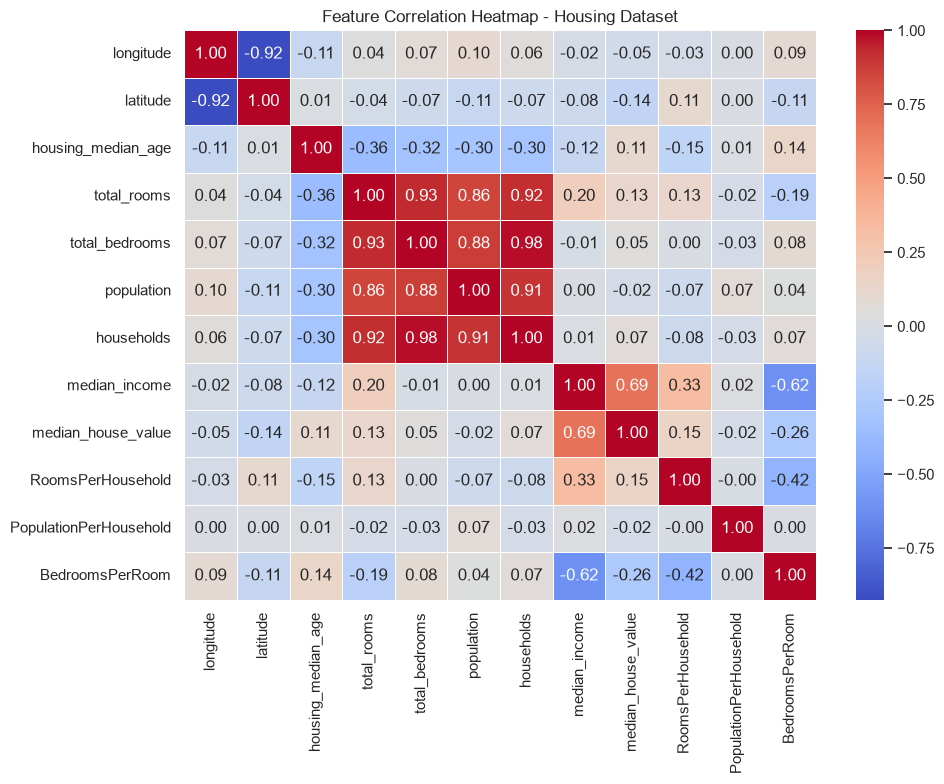

In [20]:
# Feature Engineering: Interaction Features
df['RoomsPerHousehold'] = df['total_rooms'] / df['households']
df['PopulationPerHousehold'] = df['population'] / df['households']
df['BedroomsPerRoom'] = df['total_bedrooms'] / df['total_rooms']

# Correlation Heatmap (using numeric columns)
plt.figure(figsize=(10, 8))
sns.heatmap(
    df.select_dtypes(include=[np.number]).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
)
plt.title("Feature Correlation Heatmap - Housing Dataset")
plt.tight_layout()
plt.savefig("correlation_heatmap.png")
plt.show()

## Step 5: Train-Test Split & Preprocessing Pipeline
Separate features and target, set up 80/20 train/test split, and configure a preprocessing pipeline for missing value imputation, scaling, and categorical encoding.

In [21]:
X = df.drop(columns=["median_house_value"])
y = df["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()

numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore')),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_cols),
        ('cat', categorical_transformer, categorical_cols),
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(f"Processed Training Matrix Shape: {X_train_processed.shape}")
print(f"Processed Testing Matrix Shape: {X_test_processed.shape}")

Processed Training Matrix Shape: (16512, 16)
Processed Testing Matrix Shape: (4128, 16)


## Step 6: Hyperparameter Tuning with GridSearchCV & Model Training
Fit Ridge and Lasso models across multiple alpha hyperparameters using `GridSearchCV`, alongside standard OLS Linear Regression.

In [22]:
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

alphas = [0.01, 0.1, 1.0, 10.0, 100.0]  # Slightly streamlined alpha list

# Optimized GridSearchCV with higher max_iter for speed and convergence
ridge_grid = GridSearchCV(Ridge(random_state=42), {'alpha': alphas}, cv=3, scoring='r2')
ridge_grid.fit(X_train_processed, y_train)

lasso_grid = GridSearchCV(Lasso(max_iter=2000, random_state=42), {'alpha': alphas}, cv=3, scoring='r2')
lasso_grid.fit(X_train_processed, y_train)

models = {
    "Ordinary Least Squares (OLS)": LinearRegression(),
    f"Ridge (Best α={ridge_grid.best_params_['alpha']})": ridge_grid.best_estimator_,
    f"Lasso (Best α={lasso_grid.best_params_['alpha']})": lasso_grid.best_estimator_
}

results = {}
for name, model in models.items():
    model.fit(X_train_processed, y_train)
    y_pred = model.predict(X_test_processed)

    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results[name] = {"y_pred": y_pred, "metrics": {"RMSE": rmse, "MAE": mae, "R2": r2}}
    print(f"=== {name} ===")
    print(f"  • RMSE: {rmse:,.2f} | MAE: {mae:,.2f} | R²: {r2:.4f}\n" + "-"*40)

=== Ordinary Least Squares (OLS) ===
  • RMSE: 69,127.04 | MAE: 49,645.49 | R²: 0.6353
----------------------------------------
=== Ridge (Best α=0.1) ===
  • RMSE: 69,127.87 | MAE: 49,646.29 | R²: 0.6353
----------------------------------------
=== Lasso (Best α=100.0) ===
  • RMSE: 69,179.25 | MAE: 49,648.55 | R²: 0.6348
----------------------------------------


## Step 7: Predicted vs. Actual Value Visualizations
Plot actual housing prices against predictions made by OLS, Ridge, and Lasso.

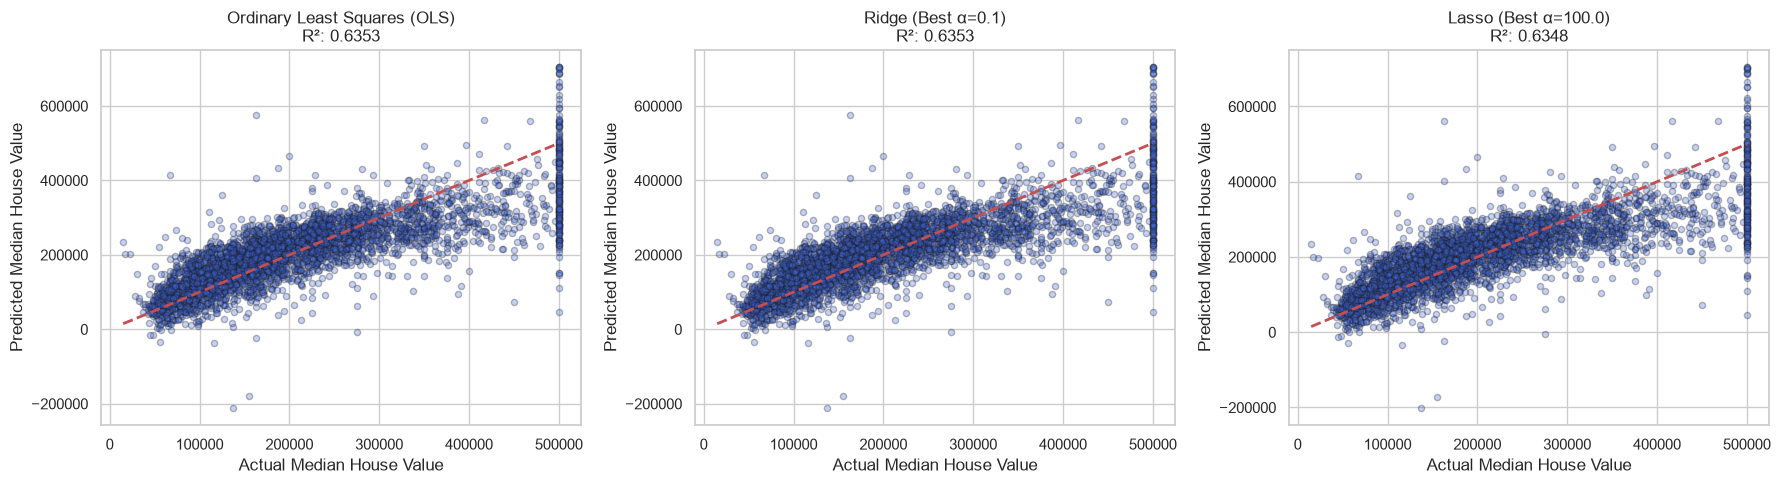

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (name, res) in enumerate(results.items()):
  ax = axes[idx]
  ax.scatter(
      y_test, res["y_pred"], alpha=0.3, color="royalblue", edgecolor="k", s=20
  )
  ax.plot(
      [y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2
  )
  ax.set_title(f"{name}\nR²: {res['metrics']['R2']:.4f}")
  ax.set_xlabel("Actual Median House Value")
  ax.set_ylabel("Predicted Median House Value")

plt.tight_layout()
plt.savefig("actual_vs_predicted.png")
plt.show()

## Step 8: Residual Distribution Curves
Plot the distribution curves of residuals (Actual - Predicted) to evaluate error normality and variance across all three models.

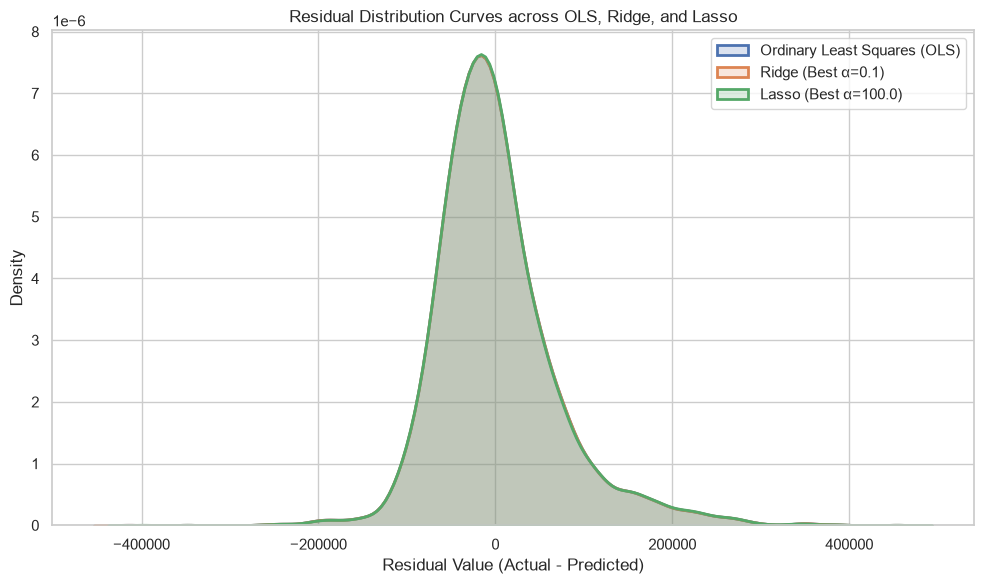

In [24]:
plt.figure(figsize=(10, 6))
for name, res in results.items():
  residuals = y_test - res["y_pred"]
  sns.kdeplot(residuals, label=name, fill=True, alpha=0.2, linewidth=2)

plt.title("Residual Distribution Curves across OLS, Ridge, and Lasso")
plt.xlabel("Residual Value (Actual - Predicted)")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.savefig("residual_distributions.png")
plt.show()